# Simulation contrasts: BVOC → SOA → cloud maps, one figure per question

**Why this notebook.** One place for every contrast between the simulations, grouped by the question it answers (user request 2026-11-07). Layout taken from the grid in `diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_FUT.ipynb`, **without the liquid water path** column: one row per contrast, one column per variable (ISOP and MTERP emissions, SOA burden, aerosol number, liquid cloud fraction, droplet effective radius, droplet number, evapotranspiration).

| Fig. | Question | Contrasts (case1 − case2) |
|---|---|---|
| 1a | Combined effect of land-cover change and climate change | LCC_FUT − CTRL_PD |
| 1b | Total effect of LCC, in PD and in FUT climate | LCC_PD − CTRL_PD · LCC_FUT − CTRL_FUT |
| 1c | Background climate change, no land-cover change | CTRL_FUT − CTRL_PD (current vegetation) · LCC_FUT − LCC_PD (future vegetation) |
| 2 | BVOC-related effects: only the prescribed emissions differ | fBVOC[lccPD − ctrlPD] in PD · fBVOC[lccFUT − ctrlFUT] in FUT · fBVOC[lccFUT − lccPD] (CC, LCC vegetation) · fBVOC[lccFUT − ctrlPD] (LCC + CC) |
| 2b | Supplementary BVOC contrasts | fBVOC[ctrlFUT − ctrlPD] (CC, current vegetation) · fBVOC[lccPD − ctrlPD] in FUT climate (not really physical) |
| 3a | Non-BVOC effects of LCC (same prescribed emissions) | [LCC_PD − CTRL_PD]_fBVOCctrlPD · [LCC_FUT − CTRL_FUT]_fBVOCctrlFUT |
| 3b | Non-BVOC effects of climate change (same prescribed emissions) | [LCC_FUT − LCC_PD]_fBVOCctrlPD · [LCC_FUT − CTRL_PD]_fBVOCctrlPD |
| 4a | Artefact on LCC land (CTRL emissions prescribed) | art_LCC_PD · art_LCC_FUT |
| 4b | Prescription artefact on CTRL land | art_CTRL_PD · art_CTRL_FUT |

**Artefacts (user 2026-11-08).** art_CTRL_P = CTRL_P − CTRL_P_fBVOCctrlP (interactive − prescribed with the run's own emissions, the design-B artefact). art_LCC_P = LCC_P − LCC_P_fBVOCctrlP: on LCC land the prescribed emissions are those of CTRL, so art_LCC also contains the BVOC effect of LCC (it is the uncorrected BVOC effect LCC − LCC_fBVOC); art_LCC_P − art_CTRL_P is the design-B corrected BVOC effect. Definitions in `ARTEFACT` (next cell).

**`LCC_FUT_fBVOClccFUT` (24g, design A) is not processed yet**, so Fig. 2 uses the design-B stand-in (user 2026-11-08) `LCC_FUT_fBVOClccFUT[design B]` = LCC_FUT − art_CTRL_FUT = LCC_FUT − CTRL_FUT + CTRL_FUT_fBVOCctrlFUT, i.e. it assumes the artefact on LCC land equals the one on CTRL land. The switch is `forcing_maps.LCC_FUT_FBVOCLCCFUT_DESIGN_B` (one place for the whole analysis, user 2026-11-08): set it to False once 24g is processed and rerun. The same contrasts, grouped by category (interactive, fBVOC, non-BVOC, artefacts), are in the topic notebooks and `results/figures/<category>/`.

**Data.** CO₂-fix (new-chain) runs, 2001–2014 (first 12 months dropped), `data/processed-data/postprocessing/<alias>_{atm,lnd}_<CLASS>_2001-2014.nc`. Maps: mean over years, view north of 45°N; each panel its own colour scale; in Figs. 1b, 1c, 3a and 4b a third row below the line = row 2 − row 1, in blue-teal (negative) → orange (positive) to set it apart from the red-blue rows; hatched = not significant (paired yearly t-test, FDR 10 %); under each map the area-weighted mean ≥45°N ± 95 % CI of the yearly means. Outputs: `simulation-contrasts_outputs/figures/`.

**Reading the emission columns.** In the fBVOC runs, ISOP and MTERP are prescribed. A contrast of two fBVOC runs with the same source (Fig. 3) has ≈ 0 emission difference by construction; FUT runs fed with CTRL_PD emissions get the PD emissions relabelled to 2100. MEGAN off also removes the other MEGAN compounds, so an interactive − fBVOC contrast is not ISOP + MTERP only.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
sys.path.insert(0, str(REPO / 'src'))
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
# map colours: RdBu_r for rows 1-2 (as in all project maps); difference rows (row 2 − row 1) only
# (user 2026-11-07): dark blue-teal (negative) - white - dark orange (positive), teal with less green
DIFF_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'blueteal_orange', ['#123E5C', '#5B8DAE', '#F7F7F7', '#DE7A3A', '#8A3A0A'])
START_YEAR, END_YEAR = 2001, 2014
OUT = Path('simulation-contrasts_outputs')
FIGDIR = OUT / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)

# context panels of how_big_artefact_is_FUT.ipynb without the liquid water path (user 2026-11-07)
PANELS = [p for p in fm.CONTEXT_PANELS if p.key != 'lwp']
NEEDED = sorted({(p.variable_class, p.component) for p in PANELS})

# artefacts as defined by the user (2026-11-08): on CTRL land with the run's own emissions, on LCC
# land with the CTRL emissions of the same period (so art_LCC also contains the LCC emission change)
ARTEFACT = {
    'art_LCC_PD':   ('LCC_PD',   'LCC_PD_fBVOCctrlPD'),
    'art_LCC_FUT':  ('LCC_FUT',  'LCC_FUT_fBVOCctrlFUT'),
    'art_CTRL_PD':  ('CTRL_PD',  'CTRL_PD_fBVOCctrlPD'),
    'art_CTRL_FUT': ('CTRL_FUT', 'CTRL_FUT_fBVOCctrlFUT'),
}

def _processed(alias):
    return all(fm.filename(alias, cls, START_YEAR, END_YEAR, comp).exists() for cls, comp in NEEDED)

# LCC_FUT_fBVOClccFUT: one switch for the whole analysis (user 2026-11-08), fm.LCC_FUT_FBVOCLCCFUT_DESIGN_B;
# design-B stand-in LCC_FUT − CTRL_FUT + CTRL_FUT_fBVOCctrlFUT until the run is processed, TO BE REPLACED
LCC_FUT_lccFUT = fm.LCC_FUT_FBVOCLCCFUT
print("LCC_FUT_fBVOClccFUT:", "design-B stand-in" if fm.LCC_FUT_FBVOCLCCFUT_DESIGN_B else "real run (design A)")

# figure id -> (title, [(case1, case2), ...])
FIGURES = {
    '1a': ('combined effect of land-cover change and climate change', [
        ('LCC_FUT', 'CTRL_PD')]),
    '1b': ('total effect of LCC, PD and FUT climate', [
        ('LCC_PD', 'CTRL_PD'),
        ('LCC_FUT', 'CTRL_FUT')]),
    '1c': ('background climate change, current (CTRL) and future (LCC) vegetation', [
        ('CTRL_FUT', 'CTRL_PD'),
        ('LCC_FUT', 'LCC_PD')]),
    '2': ('BVOC-related effects (only the prescribed emissions differ)', [
        ('LCC_PD_fBVOClccPD', 'LCC_PD_fBVOCctrlPD'),      # emission change from LCC, PD climate
        (LCC_FUT_lccFUT, 'LCC_FUT_fBVOCctrlFUT'),         # emission change from LCC, FUT climate
        (LCC_FUT_lccFUT, 'LCC_FUT_fBVOClccPD'),           # emission change from CC, LCC vegetation
        (LCC_FUT_lccFUT, 'LCC_FUT_fBVOCctrlPD')]),        # emission change from LCC + CC
    '2b': ('supplementary BVOC-related contrasts', [
        ('LCC_FUT_fBVOCctrlFUT', 'LCC_FUT_fBVOCctrlPD'),  # emission change from CC, current vegetation
        ('LCC_FUT_fBVOClccPD', 'LCC_FUT_fBVOCctrlPD')]),  # emission change from LCC, FUT climate (not physical)
    '3a': ('non-BVOC effects of LCC (same prescribed emissions)', [
        ('LCC_PD_fBVOCctrlPD', 'CTRL_PD_fBVOCctrlPD'),
        ('LCC_FUT_fBVOCctrlFUT', 'CTRL_FUT_fBVOCctrlFUT')]),
    '3b': ('non-BVOC effects of climate change (CTRL_PD emissions prescribed)', [
        ('LCC_FUT_fBVOCctrlPD', 'LCC_PD_fBVOCctrlPD'),
        ('LCC_FUT_fBVOCctrlPD', 'CTRL_PD_fBVOCctrlPD')]),
    '4a': ('artefact on LCC land (interactive − CTRL emissions of the period prescribed)', [
        ARTEFACT['art_LCC_PD'], ARTEFACT['art_LCC_FUT']]),
    '4b': ('prescription artefact on CTRL land (interactive − own emissions prescribed)', [
        ARTEFACT['art_CTRL_PD'], ARTEFACT['art_CTRL_FUT']]),
}

ALIASES = sorted({a for _, rows in FIGURES.values() for pair in rows for x in pair for a in fm.run_weights(x)})
AVAILABLE = {a: _processed(a) for a in ALIASES}
for a in ALIASES:
    print(f'{a:28s}', '✓' if AVAILABLE[a] else 'MISSING (not run or not processed)')

# figures that get a third row = row 2 − row 1 (user 2026-11-07), drawn below a horizontal line.
# (A − B) − (C − D) is plotted as VirtualRun(A + D − C) − B; derived fields are computed per real
# pair and the yearly differences combined before the paired t-test (fm.VirtualRun).
DIFF_FIGURES = ('1b', '1c', '3a', '3b', '4b')

# row labels on the left (user 2026-11-08): the shared part factored out, e.g. CTRL_FUT − CTRL_PD → CTRL_[FUT − PD]
ART_NAME = {pair: name for name, pair in ARTEFACT.items()}

def short_label(c1, c2):
    if getattr(c1, 'diff_row', False):
        return c1.short
    tag = ''
    if isinstance(c1, fm.VirtualRun):            # design-B stand-in
        c1, tag = c1.split('[')[0], '\n(design B)'
    c1, c2 = str(c1), str(c2)
    if (c1, c2) in ART_NAME:
        return ART_NAME[(c1, c2)]
    if '_fBVOC' in c1 and '_fBVOC' in c2:
        (r1, s1), (r2, s2) = c1.split('_fBVOC'), c2.split('_fBVOC')
        if r1 == r2:                              # same run, different prescribed emissions
            return f'{r1}_fBVOC\n[{s1} − {s2}]' + tag
        if s1 == s2:                              # different runs, same prescribed emissions
            return f'[{r1} − {r2}]\n_fBVOC{s1}' + tag
    if '_fBVOC' not in c1 + c2:
        (v1, p1), (v2, p2) = c1.split('_'), c2.split('_')
        if p1 == p2:
            return f'[{v1} − {v2}]_{p1}'
        if v1 == v2:
            return f'{v1}_[{p1} − {p2}]'
    return f'{c1} − {c2}' + tag

def diff_row(row1, row2):
    (c, d), (a, b) = row1, row2
    weights = {}
    for alias, w in ((a, 1.0), (d, 1.0), (c, -1.0)):   # accumulate: aliases can repeat (Fig. 3b)
        weights[alias] = weights.get(alias, 0.0) + w
    weights = {k: w for k, w in weights.items() if w != 0}
    label = f'({a} − {b})\n− ({c} − {d})'
    v = fm.VirtualRun(label, weights)
    one_line = lambda x, y: short_label(x, y).replace('\n_', '_').replace('\n', ' ')
    v.short = f'{one_line(a, b)}\n− {one_line(c, d)}'
    v.diff_row = True   # marks the row-2 − row-1 rows (own colour map, line above); design-B stand-ins are not
    return v, b

for fid in DIFF_FIGURES:
    title, rows = FIGURES[fid]
    FIGURES[fid] = (title, rows[:2] + [diff_row(rows[0], rows[1])])


LCC_FUT_fBVOClccFUT not processed -> design B: LCC_FUT − CTRL_FUT + CTRL_FUT_fBVOCctrlFUT
CTRL_FUT                     ✓
CTRL_FUT_fBVOCctrlFUT        ✓
CTRL_PD                      ✓
CTRL_PD_fBVOCctrlPD          ✓
LCC_FUT                      ✓
LCC_FUT_fBVOCctrlFUT         ✓
LCC_FUT_fBVOCctrlPD          ✓
LCC_FUT_fBVOClccPD           ✓
LCC_PD                       ✓
LCC_PD_fBVOCctrlPD           ✓
LCC_PD_fBVOClccPD            ✓


In [2]:
import contextlib, io

PENDING_NOTE = {
    'LCC_FUT_fBVOClccFUT': 'run 24g in progress (launched 2026-11-06), processed automatically when done',
}

def plot_figure(fig_id):
    """All rows of the figure; a row whose runs are not processed yet stays empty with a 'pending' label."""
    title, rows = FIGURES[fig_id]
    real = lambda r: [a for x in r for a in fm.run_weights(x)]
    pending = {r: [a for a in dict.fromkeys(real(r)) if not AVAILABLE[a]] for r in rows}
    if all(pending.values()):
        print(f'Fig. {fig_id}: no row available yet')
    buf = io.StringIO()
    plot_panel = fm._plot_panel
    def diff_cmap_panel(ax, panel, pairs, *args, **kw):   # DIFF_CMAP on difference rows only
        if getattr(pairs['case1'], 'diff_row', False):
            kw['cmap'] = DIFF_CMAP
        return plot_panel(ax, panel, pairs, *args, **kw)
    fm._plot_panel = diff_cmap_panel
    try:
        with contextlib.redirect_stdout(buf):   # hides the per-panel 'Skipping … missing' lines of pending rows
            fig, axes = fm.make_contrast_grid_figure(title, PANELS, f'Fig. {fig_id}', rows=rows,
                                                     start_year=START_YEAR, end_year=END_YEAR, save=False)
    finally:
        fm._plot_panel = plot_panel
    for line in buf.getvalue().splitlines():
        if not any(a in line for miss in pending.values() for a in miss):
            print(line)
    for i, r in enumerate(rows):
        if pending[r]:
            note = '; '.join(f'{a}: {PENDING_NOTE.get(a, "not processed yet")}' for a in pending[r])
            print(f'Pending row: {r[0]} − {r[1]}  ({note})')
            ax = axes[i][len(PANELS) // 2]
            ax.text(0.5, 0.5, f'PENDING\n{note}', transform=ax.transAxes, ha='center', va='center',
                    fontsize=12, color='0.35', fontweight='bold')
    for i, (c1, c2) in enumerate(rows):
        for t in axes[i][0].texts:              # row label on the left → short name of the difference
            if t.get_text().startswith(str(c1)):
                t.set_text(short_label(c1, c2))
        if getattr(c1, 'diff_row', False):   # difference row: line above it
            top = max(ax.get_position().y1 for ax in axes[i])
            above = [a.get_position().y0 for a in fig.axes if a.get_position().y0 > top]
            y = (top + min(above)) / 2 if above else top
            fig.add_artist(Line2D([0.01, 0.99], [y, y], transform=fig.transFigure, color='0.2', lw=1.5))
    path = FIGDIR / f'contrast_grid_fig{fig_id}_{START_YEAR}_{END_YEAR}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight')
    print(f'Saved {path}')
    plt.show(); plt.close(fig)

## 1a. Combined effect of land-cover change and climate change
`LCC_FUT − CTRL_PD`: future vegetation in the future climate vs present vegetation in the present climate. The climate part dominates most variables; compare with 1b and 1c.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved simulation-contrasts_outputs/figures/contrast_grid_fig1a_2001_2014.png


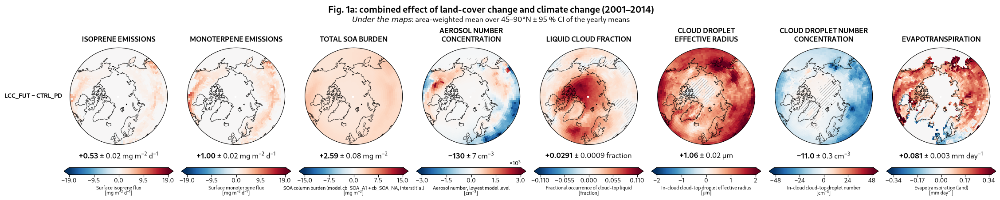

In [3]:
plot_figure('1a')

## 1b. Total effect of LCC only
- `LCC_PD − CTRL_PD`: total effect of LCC in PD climate.
- `LCC_FUT − CTRL_FUT`: total effect of LCC in FUT climate.

Both contain the BVOC part (Fig. 2) and the non-BVOC part (Fig. 3a).

**Row 3 — does the total LCC effect change between PD and FUT?** `(LCC_FUT − CTRL_FUT) − (LCC_PD − CTRL_PD)` = how the total response to the same imposed LCC changes in the future background, including surface and BVOC-mediated pathways. Positive = the LCC effect is larger (or less negative) in FUT.

Saved simulation-contrasts_outputs/figures/contrast_grid_fig1b_2001_2014.png


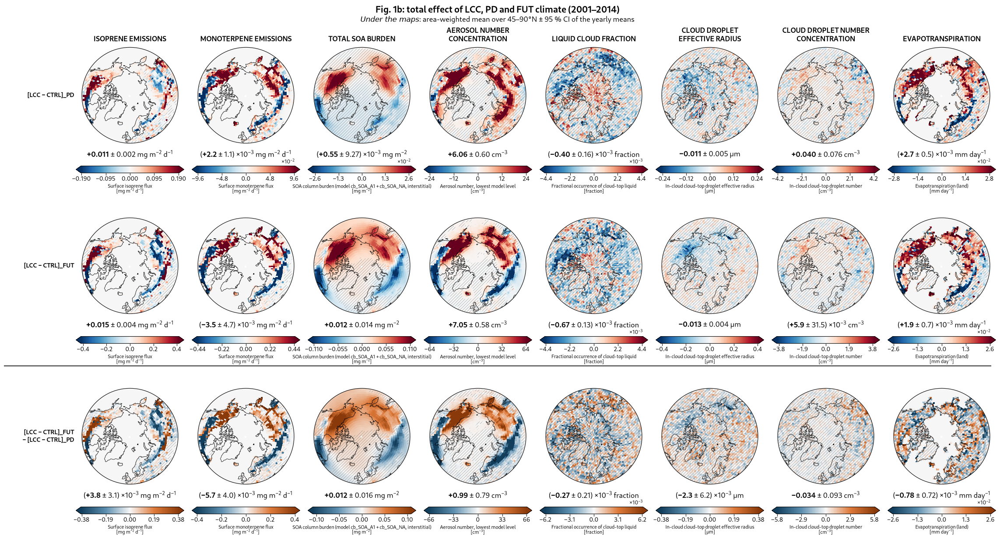

In [4]:
plot_figure('1b')

## 1c. Background climate change, no land-cover change
How the system responds to the future background (SST, GHG, emissions):
- `CTRL_FUT − CTRL_PD`: with current vegetation (PV).
- `LCC_FUT − LCC_PD`: with future vegetation (FV).

**Row 3 — does the climate-change response depend on the vegetation?** `(LCC_FUT − LCC_PD) − (CTRL_FUT − CTRL_PD)`. Algebraically the **same quantity as row 3 of Fig. 1b** (both = LCC_FUT − CTRL_FUT − LCC_PD + CTRL_PD, the LCC × climate interaction), so the two maps are identical; here it reads as the vegetation dependence of the climate response.

Saved simulation-contrasts_outputs/figures/contrast_grid_fig1c_2001_2014.png


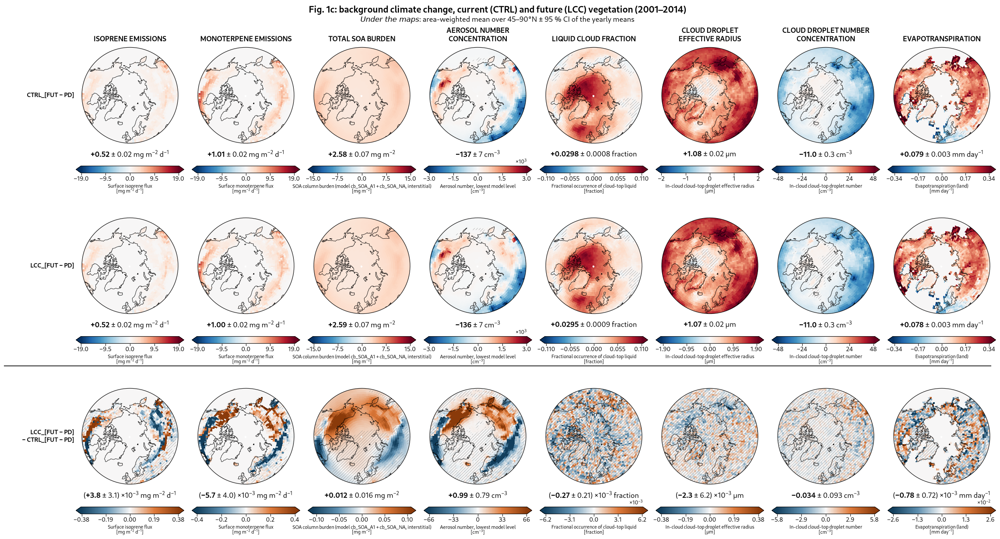

In [5]:
plot_figure('1c')

## 2. BVOC-related effects
Both runs of each row have the same land and the same climate; only the prescribed emissions differ, so the prescription artefact cancels.

| Row | Notation | Driver |
|---|---|---|
| `LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD` | LCC_PD_fBVOC [lccPD − ctrlPD] | BVOC emission change from LCC, PD climate |
| `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlFUT` | LCC_FUT_fBVOC [lccFUT − ctrlFUT] | BVOC emission change from LCC, FUT climate |
| `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOClccPD` | LCC_FUT_fBVOC [lccFUT − lccPD] | BVOC emission change from CC, perturbed vegetation |
| `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlPD` | LCC_FUT_fBVOC [lccFUT − ctrlPD] | BVOC emission change from LCC and CC together |

Rows 2–4: `LCC_FUT_fBVOClccFUT` (24g) is not processed yet, so they use the design-B stand-in `LCC_FUT_fBVOClccFUT[design B]` = LCC_FUT − CTRL_FUT + CTRL_FUT_fBVOCctrlFUT (= LCC_FUT − art_CTRL_FUT). Row 2 then equals (LCC_FUT − LCC_FUT_fBVOCctrlFUT) − art_CTRL_FUT, the design-B corrected BVOC effect in FUT. With the stand-in the prescription artefact no longer cancels exactly; the residual is art(LCC land) − art(CTRL land).

Saved simulation-contrasts_outputs/figures/contrast_grid_fig2_2001_2014.png


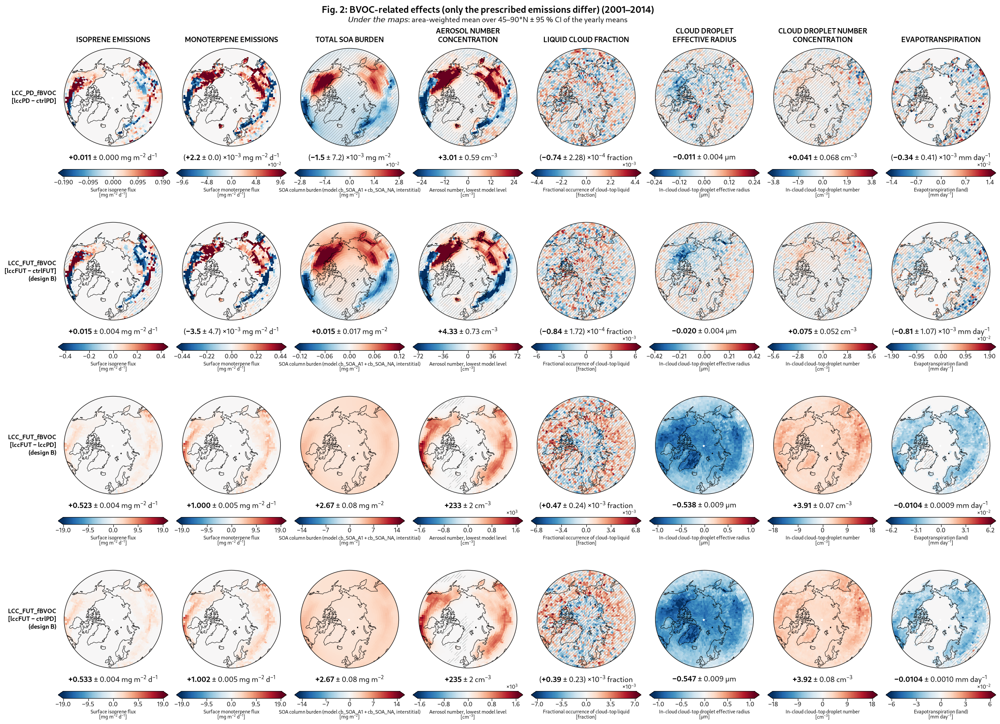

In [6]:
plot_figure('2')

## 2b. Supplementary BVOC-related contrasts
| Row | Notation | Driver |
|---|---|---|
| `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` | LCC_FUT_fBVOC [ctrlFUT − ctrlPD] | BVOC emission change from CC, current vegetation |
| `LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD` | LCC_FUT_fBVOC [lccPD − ctrlPD] | BVOC emission change from LCC (PD emissions), in FUT climate; not really physical |

Saved simulation-contrasts_outputs/figures/contrast_grid_fig2b_2001_2014.png


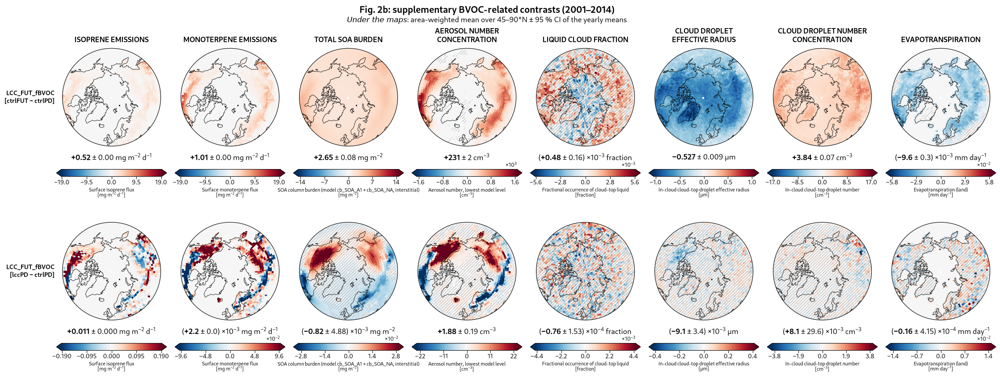

In [7]:
plot_figure('2b')

## 3a. Non-BVOC effects of LCC
Same prescribed emissions in both runs, so the emission columns are ≈ 0 and what remains is the biogeophysical (non-BVOC) effect of the land-cover change.
- `[LCC_PD − CTRL_PD]_fBVOCctrlPD` = `LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD`
- `[LCC_FUT − CTRL_FUT]_fBVOCctrlFUT` = `LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT`

**Row 3 — does the fixed-BVOC LCC response change between PD and FUT?** `(LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT) − (LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD)` = how the LCC response changes between PD and FUT when the LCC-induced BVOC emission change is suppressed in each background.

Saved simulation-contrasts_outputs/figures/contrast_grid_fig3a_2001_2014.png


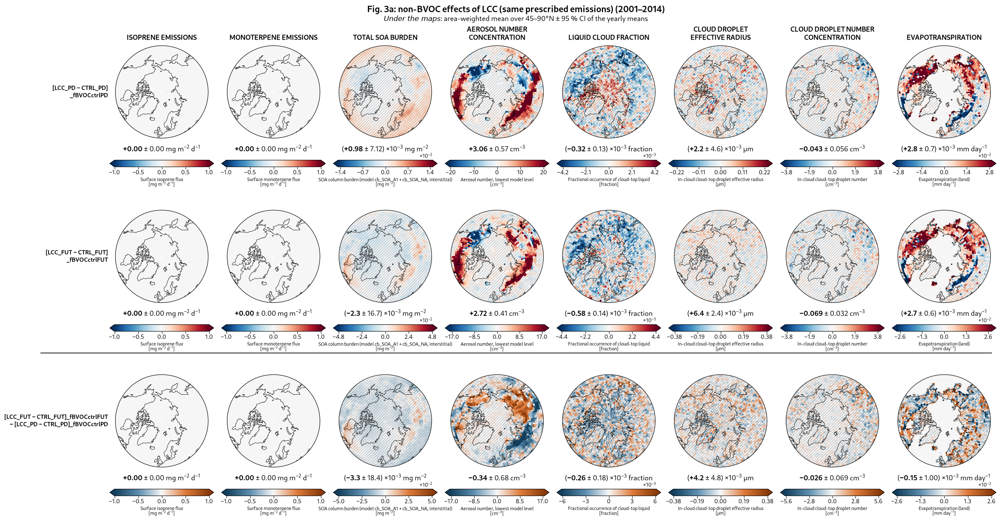

In [8]:
plot_figure('3a')

## 3b. Non-BVOC effects of climate change
Both runs prescribe CTRL_PD emissions (relabelled to 2100 in FUT), so the BVOC emission response to the climate is switched off.
- `[LCC_FUT − LCC_PD]_fBVOCctrlPD` = `LCC_FUT_fBVOCctrlPD − LCC_PD_fBVOCctrlPD`: climate change on LCC land.
- `[LCC_FUT − CTRL_PD]_fBVOCctrlPD` = `LCC_FUT_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD`: land-cover change and climate change together, with fixed (CTRL_PD) emissions; the non-BVOC counterpart of Fig. 1a.

**Row 3 — difference row 2 − row 1:** `[LCC_FUT − CTRL_PD]_fBVOCctrlPD − [LCC_FUT − LCC_PD]_fBVOCctrlPD`. LCC_FUT_fBVOCctrlPD cancels, so this is algebraically **the same as row 1 of Fig. 3a** (`[LCC_PD − CTRL_PD]_fBVOCctrlPD`, the non-BVOC effect of LCC in PD climate).

Saved simulation-contrasts_outputs/figures/contrast_grid_fig3b_2001_2014.png


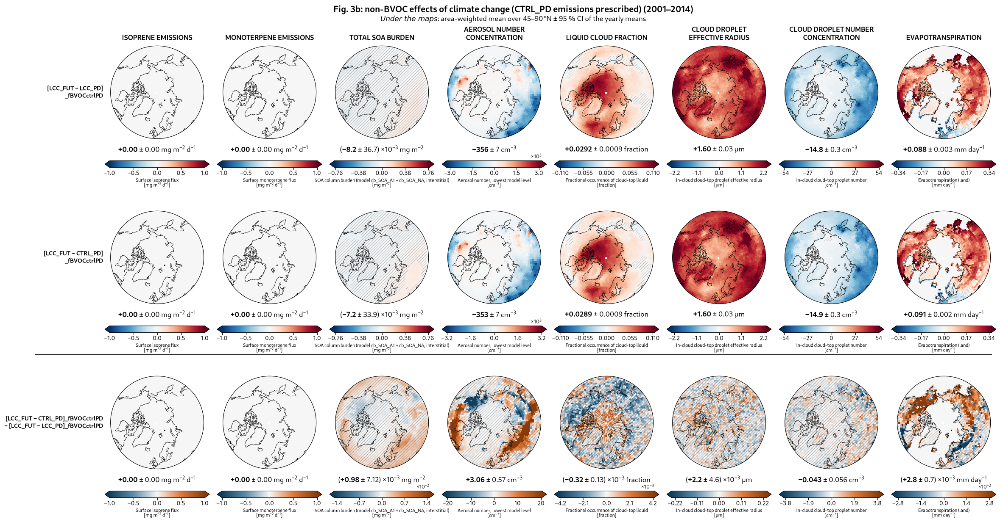

In [9]:
plot_figure('3b')

## 4a. Artefacts on LCC land
- art_LCC_PD = `LCC_PD − LCC_PD_fBVOCctrlPD`
- art_LCC_FUT = `LCC_FUT − LCC_FUT_fBVOCctrlFUT`

Interactive LCC run minus the LCC run with the **CTRL emissions of the same period** prescribed. These are the uncorrected BVOC effects: they contain the BVOC emission change from LCC plus the prescription artefact. Subtracting Fig. 4b (art_CTRL) gives the design-B corrected BVOC effect.

Saved simulation-contrasts_outputs/figures/contrast_grid_fig4a_2001_2014.png


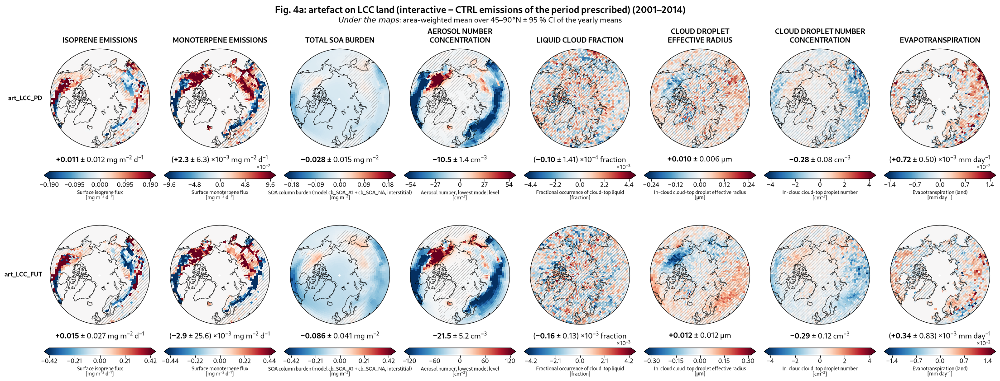

In [10]:
plot_figure('4a')

## 4b. Artefacts on CTRL land
- art_CTRL_PD = `CTRL_PD − CTRL_PD_fBVOCctrlPD`
- art_CTRL_FUT = `CTRL_FUT − CTRL_FUT_fBVOCctrlFUT`

The design-B correction subtracts these: corrected BVOC effect = art_LCC_P (Fig. 4a) − art_CTRL_P. The design-B assumption art(LCC land) ≈ art(CTRL land) is tested in `diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_PD.ipynb`.

**Row 3 — does the artefact on CTRL land change between PD and FUT?** `(CTRL_FUT − CTRL_FUT_fBVOCctrlFUT) − (CTRL_PD − CTRL_PD_fBVOCctrlPD)`. Close to zero means one artefact correction behaves the same in both backgrounds.

Saved simulation-contrasts_outputs/figures/contrast_grid_fig4b_2001_2014.png


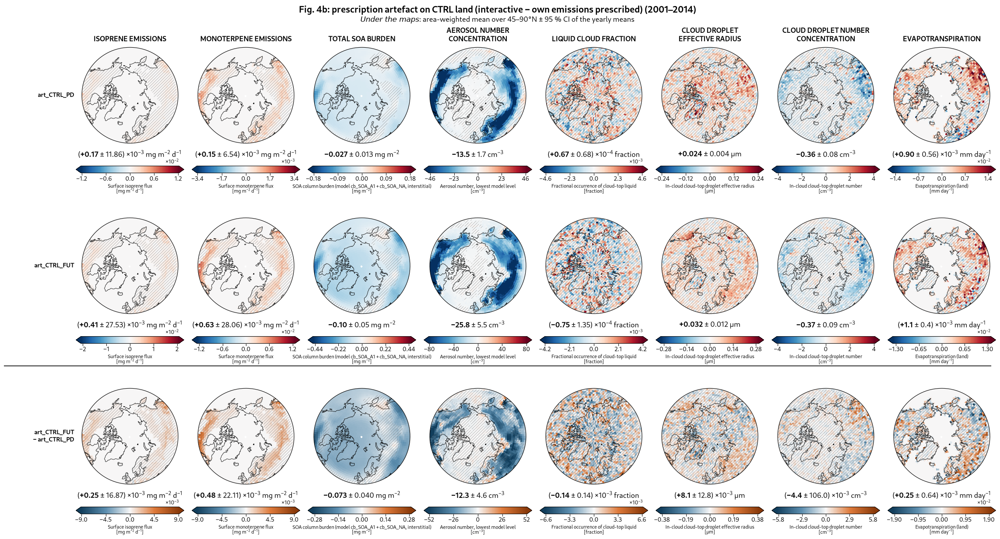

In [11]:
plot_figure('4b')